# Fixed failure prices and the wear benchmark

An asset earns utility by operating and consumes a wear allowance before independent maintenance access. We evaluate two fixed operating rules and compare them with policies from a dynamic program on a discretized state and action space. The discretized problem provides a benchmark for the stated prices. Its simulator estimates are subject to Monte Carlo error.

The notebook checks the clipped-return identity, shows how a comparison policy enters a price–risk calculation, and validates one candidate. An episode under the independent maintenance clock gives a Bernoulli observation of geometric risk $q_\beta$. We use the resulting bound with $p_T\le\beta^{-T}q_\beta$ when assessing a finite-horizon tolerance. [Theory guide](../../docs/under-the-hood/decisions-and-theory.md)

This notebook uses NumPy, SciPy and Matplotlib. T2 trains PPO on the same task.

## The optimization problem and the benchmark

The state is the price index $s_t\in[-1,1]$ and the remaining wear allowance $z_t$. The actor selects operating rate $a_t\in[0,1]$. Utility is $u_t=(1+0.5s_t)a_t/1.5$. The next index is $0.8s_t+0.2W_t$, with $W_t$ uniform on $[-1,1]$. Consumption is $0.1a_t X_t$ with a gamma wear shock $X_t$ of shape $0.5$ and scale $2$. Take $z_0=1$ and $\beta=0.95$. Let $\tau$ be the first action with $z_{t+1}=z_t-0.1a_tX_t<0$. Set $\tau=\infty$ if no such action occurs.

Let $U$ denote expected discounted utility before failure and $\mathcal I_m$ the expected discounted interior deduction. Let $\Pi$ denote the policy class and $q_\beta=\mathbb E_\pi[\beta^\tau\mathbf1_{\{\tau<\infty\}}]$. The continuing priced problem is

$$
\underset{\pi\in\Pi}{\mathrm{maximize}}\quad U(\pi)-\mathcal I_m(\pi)-\frac{m}{1-\beta}q_\beta(\pi).
$$

The corresponding deployment problem at a fixed horizon is

$$
\begin{aligned}
\underset{\pi\in\Pi}{\mathrm{maximize}}\quad & U(\pi)\\
\text{subject to}\quad & \Pr_\pi(\tau\le19)\le0.05.
\end{aligned}
$$

The grid benchmark approximates the priced problem for specified prices. For a state and trial action, its Bellman calculation averages the failure charge $-m/(1-\beta)$ on crossing outcomes and $r_m+\beta V(s',z')$ on surviving outcomes. It maximizes the resulting action values at each grid point and iterates the value calculation. The selected grid policies are evaluated in the continuous simulator. [Bellman recursion for an exact finite model](../../docs/dynamic-programming.md)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import barrierpg
from barrierpg import BudgetSpec, Requirement, Stage, plan, evaluate, interpret, LogBarrier
from barrierpg.examples.wear import WearModel, make_wear_env, standing_still_policy, IncumbentRule, EXACT_FRONTIER, EXACT_BARRIER

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
print("barrierpg", barrierpg.__version__, "| checked against the paper's", barrierpg.PAPER["checked_against"])

barrierpg 0.9.0 | checked against the paper's revision 78 (2026-11-20)


## The problem: an asset operated under a wear allowance

An asset earns revenue in proportion to its **operating rate** $a\in[0,1]$ and a market price index $s$.
Each unit of throughput consumes a random part of a **wear allowance** $b=1$. Exhausting the allowance
before the next maintenance access is a **breakdown**. Maintenance access arrives with probability
$1-\beta=0.05$ per period, so the **geometric risk** $q_\beta=\mathbb E[\beta^\tau 1\{\tau<\infty\}]$ is
exactly the probability of a breakdown before access. Standing still never fails and earns nothing;
every positive rate can fail, because the wear shock is unbounded. This is the paper's running example.

`BudgetSpec` states the budget, the utility discount $\beta$ and a valid upper bound $\bar u$ on the one-step
utility. Every certificate needs $\bar u$.

In [2]:
model = WearModel()
spec = model.spec(ubar=1.0)
print(spec)

BudgetSpec(budgets=(1.0,), beta=0.95, ubar=1.0, gammas=(1.0,), u_minus=0.0, horizon=None)


## Reward with an interior barrier

The wrapper carries the remaining reserve $z$ in the state and replaces the reward by
$$r_m=\max\{-m,\;u-B(z')\},\qquad B(z')=\theta_B\log(1+b/z'),$$
with $z'$ the reserve after the action. An unclipped singular barrier can give infinite expected loss;
clipping at $-m$ keeps returns finite. From failure onward every reward is $-m$, so $m$ is a **price of failure
risk**: one unit of geometric risk costs $m/(1-\beta)$. Before failure, the barrier subtracts an **interior loss**
that keeps a reserve; a failure-only price ($\theta_B=0$) charges nothing before failure. The plotted label $\theta$ and the API argument `Stage.theta` both denote the barrier scale $\theta_B$.

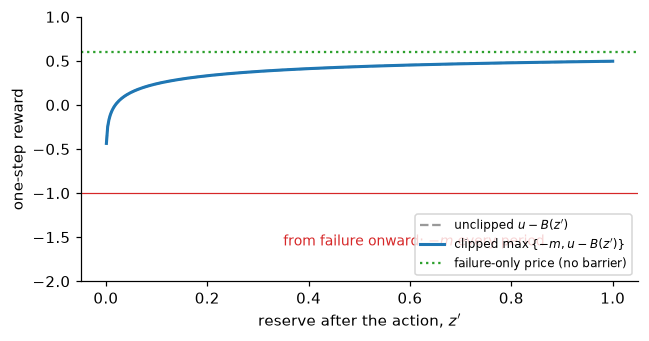

In [3]:
u, m, theta = 0.6, 1.0, 0.15
z = np.linspace(1e-3, 1.0, 400)
B = np.array([LogBarrier(theta, [1.0])([zz]) for zz in z])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(z, u - B, color="0.6", ls="--", label="unclipped $u-B(z')$")
ax.plot(z, np.maximum(-m, u - B), color="C0", lw=2, label="clipped $\\max\\{-m, u-B(z')\\}$")
ax.axhline(u, color="C2", ls=":", label="failure-only price (no barrier)")
ax.axhline(-m, color="C3", lw=0.8)
ax.annotate("from failure onward: $-m$ every period", (0.35, -m), xytext=(0.35, -1.6), color="C3", fontsize=9)
ax.set_ylim(-2, 1); ax.set_xlabel("reserve after the action, $z'$"); ax.set_ylabel("one-step reward"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## Decomposition of the clipped value

Splitting the discounted sum of clipped rewards at the failure time gives the exact identity
$$V_m=U-\mathcal I_m-\frac{m}{1-\beta}\,q_\beta ,$$
with $U$ the **stopped utility** (earned before failure) and $\mathcal I_m$ the interior loss. Let us check it
on simulated episodes: the wrapper records the clipped return of each episode, and `evaluate` computes the
right-hand side from $U$, $\mathcal I_m$ and the failure indicator.

The wear wrapper uses **geometric stopping**: each period ends the episode with probability $1-\beta$.
With algorithmic discount one the rollout objective equals the discounted objective in expectation. The failure indicator of an
episode has probability $q_\beta$.

In [4]:
barrier_stage = Stage(m=1.0, theta=0.1)
rule = IncumbentRule(span=1.5, std=0.1, seed=0)          # a rate proportional to the remaining allowance
ev = evaluate(lambda: make_wear_env(barrier_stage, model), rule, 5000, spec=spec, stage=barrier_stage, seed=0)
print(ev.summary())
print(f"\nmean clipped return {ev.clipped_returns.mean():.4f}  vs  U - I_m - m q/(1-beta) = {ev.V_m:.4f}")
print("largest per-episode difference:", float(np.max(np.abs(ev.clipped_returns - ev.V_episodes))))

n=5000: p_T censored by the geometric clock (370 failures counted for q_beta), q_beta=0.074, U=3.991±0.031, I_m=2.991, V_m=-0.4795±0.1, mean length 19.0
small reserve (min reserve <=): 0.02b: 0.101, 0.05b: 0.151, 0.1b: 0.225, 0.2b: 0.348

mean clipped return -0.4795  vs  U - I_m - m q/(1-beta) = -0.4795
largest per-episode difference: 1.4210854715202004e-14


## State the requirement, then plan

The requirement comes first: the breakdown probability within $T+1=20$ periods must stay below $\alpha=5\%$, and
the validation may be wrong with probability $\zeta=5\%$. Several candidates will be validated, so the error is
shared by a **family** of statements.

`plan` turns this into a configuration with reasons. It derives a conservative starting price from the
**price–risk bound** (a part of the paper's *Fixed price of failure risk*), using a comparison policy that never fails
(standing still) and an upper bound on the utility at stake. It also sizes the validation sample and states the
cases of the paper's *Which formulation to prefer* in which another method is the better choice.

In [5]:
req = Requirement(T=19, alpha=0.05, zeta=0.05, family=6)   # six candidates will be inspected
sup_U = spec.ubar / (1 - spec.beta)    # an upper bound on the continuous-model stopped utility
p = plan(spec, req, sup_U=sup_U, expected_failure_rate=0.01, validation_H=300, validation_N=20000,
         allowance_error_known=False, failure_permissible_at_deployment=True, model_known_and_small=True)
print(p.explain())

Requirement: p_T <= 0.05 at T = 19 (20 actions), validation error 0.05 shared by 6 statements; kind = finite.
When another method is the better choice [paper, 'Which formulation to prefer']:
  [does not apply] no failure is permissible and a controlled-invariant set is known: an almost-sure method (an infinite failure penalty, a control-barrier safety layer, or a method that learns which actions keep probability-one budget constraints). Reason: a finite price prices failure risk and does not prohibit failure; a class of full-support policies can have a positive lower bound on its risk.
  [not stated] a prescribed level is attainable with slack and the multiplier's step can be tuned: an adaptive multiplier (a Lagrangian chance-constrained policy gradient). Reason: a fixed price sets the utility-risk trade-off. The exact dual has no finite minimizer if the risk has a positive infeasibility gap.
  [not stated] approximate expected-cost control during updates matters: constrained policy op

The model is known, so dynamic programming on a grid gives a benchmark for the candidates.

This calculation uses a uniform utility bound. An optimization gap still has to be justified, and validation assesses the returned policy. Below we use $m=1$.

## Candidates against the grid benchmark

A **candidate** is one fixed policy that may be deployed. Here the candidates are hand-made rules: standing
still, and rules that run at a rate proportional to the remaining allowance, $a=\min\{1, z/(\text{span}\cdot b)\}$.
The plotted points are the grid-based wear benchmark across prices. A true fixed-price optimum is optimal at its attained risk under the conditions of *Fixed price of failure risk*.

In [6]:
stage = Stage(m=1.0)
env = lambda: make_wear_env(stage, model)
candidates = {"standing still": standing_still_policy}
for span in (1.0, 1.5, 2.0, 3.0, 5.0):
    candidates[f"rule, span {span:g}"] = IncumbentRule(span=span, std=0.1, seed=1)
evals = {name: evaluate(env, pol, 6000, spec=spec, stage=stage, seed=10, T=19) for name, pol in candidates.items()}
for name, e in evals.items():
    print(f"{name:14s} q_beta = {e.q_beta:.4f}   U = {e.U:.3f}   reserve below 5% of b =  {e.near[0.05]:.3f}")

standing still q_beta = 0.0000   U = 0.000   reserve below 5% of b =  0.000
rule, span 1   q_beta = 0.1723   U = 4.648   reserve below 5% of b =  0.298
rule, span 1.5 q_beta = 0.0710   U = 3.971   reserve below 5% of b =  0.149
rule, span 2   q_beta = 0.0365   U = 3.467   reserve below 5% of b =  0.076
rule, span 3   q_beta = 0.0100   U = 2.760   reserve below 5% of b =  0.024
rule, span 5   q_beta = 0.0013   U = 1.959   reserve below 5% of b =  0.005


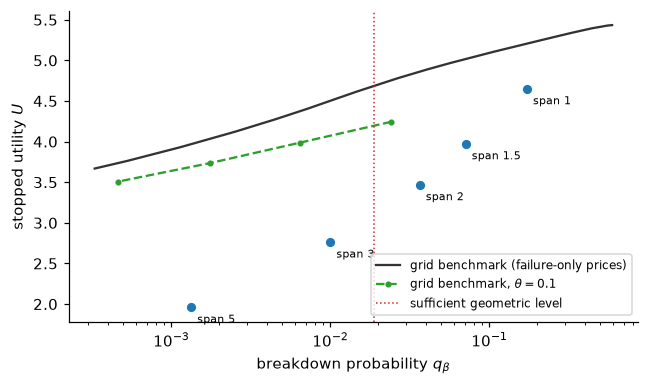

In [7]:
qf = np.array([v[0] for k, v in EXACT_FRONTIER.items()]); Uf = np.array([v[1] for k, v in EXACT_FRONTIER.items()])
order = np.argsort(qf)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(qf[order], Uf[order], color="0.2", lw=1.5, label="grid benchmark (failure-only prices)")
qb = [v[0] for v in EXACT_BARRIER.values()]; Ub = [v[1] for v in EXACT_BARRIER.values()]
ax.plot(qb, Ub, color="C2", ls="--", marker=".", label="grid benchmark, $\\theta=0.1$")
for name, e in evals.items():
    if name != "standing still":
        ax.plot(e.q_beta, e.U, "o", color="C0", ms=5)
        ax.annotate(name.replace("rule, ", ""), (e.q_beta, e.U), textcoords="offset points", xytext=(4, -10), fontsize=7)
ax.axvline(req.alpha * spec.beta ** req.T, color="C3", ls=":", lw=1, label="sufficient geometric level")
ax.set_xscale("log"); ax.set_xlabel("breakdown probability $q_\\beta$"); ax.set_ylabel("stopped utility $U$")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

Compare the rules' estimated utility at their measured risk with the grid curves. Notebook T2 measures the protection under a smaller allowance.

## A plug-in price–risk calculation

We plug the no-price benchmark utility into the price–risk expression, as in the wear study. The comparison assumes zero gap for illustration. The grid data do not establish those assumptions for the continuous model.

plug-in comparison across prices:
plug-in estimate / benchmark risk at m = 1, 10: [18.7, 23.6]


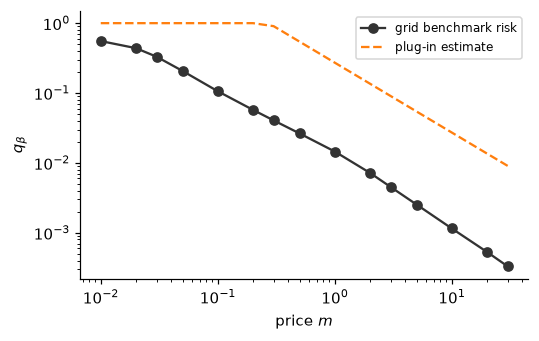

In [8]:
from barrierpg.frontier import Run, check_runs
runs = [Run(m=mm, q_beta=q, U=U, label="grid") for mm, (q, U) in EXACT_FRONTIER.items() if mm > 0]
chk = check_runs(runs, beta=spec.beta, sup_U=EXACT_FRONTIER[0.0][1], delta=0.0)
print("plug-in comparison across prices:")
ms = np.array([r["m"] for r in chk.table]); qs = np.array([r["q_beta"] for r in chk.table]); law = np.array([r["price_risk_bound"] for r in chk.table])
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.loglog(ms, qs, "o-", color="0.2", label="grid benchmark risk")
ax.loglog(ms, law, "--", color="C1", label="plug-in estimate")
ax.set_xlabel("price $m$"); ax.set_ylabel("$q_\\beta$"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print("plug-in estimate / benchmark risk at m = 1, 10:", [round(float(l / q), 1) for l, q, mm in zip(law, qs, ms) if mm in (1.0, 10.0)])

The plug-in expression decays as $1/m$. The printed ratios describe how far above the grid risk it lies at the two prices.

## Validate the candidate that would be deployed

Validation is the deployment decision. Draw fresh episodes of the fixed candidate and compute a one-sided exact
binomial upper bound on its failure probability. With error $\zeta_0$ per statement, zero failures in $N$ episodes
give the upper bound $1-\zeta_0^{1/N}$. The total error $\zeta$ is split over the family of candidates inspected, before any is
selected. Failure to certify does not prove a violation.

Under geometric stopping the episode clock censors the finite-horizon risk $p_T$, so the toolbox validates
$q_\beta$ and uses $p_T\le\beta^{-T}q_\beta$. Notebook T4 shows how to validate $p_T$ directly.

In [9]:
for name, e in evals.items():
    v = e.validate(req.alpha * spec.beta ** req.T, req.zeta, req.family)
    print(f"{name:14s} {v.failures:4d} failures / {v.n}: upper bound on q_beta {v.upper:.4f} -> "
          f"{'certifies' if v.passed else 'does not certify'} p_19 <= 0.05 (zero failures would certify {v.zero_failure_bound:.4f})")

standing still    0 failures / 6000: upper bound on q_beta 0.0008 -> certifies p_19 <= 0.05 (zero failures would certify 0.0008)
rule, span 1   1034 failures / 6000: upper bound on q_beta 0.1843 -> does not certify p_19 <= 0.05 (zero failures would certify 0.0008)
rule, span 1.5  426 failures / 6000: upper bound on q_beta 0.0793 -> does not certify p_19 <= 0.05 (zero failures would certify 0.0008)
rule, span 2    219 failures / 6000: upper bound on q_beta 0.0427 -> does not certify p_19 <= 0.05 (zero failures would certify 0.0008)
rule, span 3     60 failures / 6000: upper bound on q_beta 0.0135 -> certifies p_19 <= 0.05 (zero failures would certify 0.0008)
rule, span 5      8 failures / 6000: upper bound on q_beta 0.0030 -> certifies p_19 <= 0.05 (zero failures would certify 0.0008)


## The report

`interpret` writes what the evidence establishes for one candidate and what it does not. When the optimization
error is unknown (`delta=None`), as for a hand-made rule, the report makes no optimality claim; validation is the
operative evidence.

In [10]:
inc = evals["rule, span 3"]
rep = interpret(spec, req, stage, inc, sup_U=sup_U, delta=None, candidate_name="the span-3 rule")
print(rep.text())

Candidate under price m = 1; requirement p_19 <= 0.05 at error 0.05/6.

Measured on fresh episodes:
  n=6000: p_T censored by the geometric clock (60 failures counted for q_beta), q_beta=0.01, U=2.76±0.024, I_m=0, V_m=2.56±0.032, mean length 20.1
  small reserve (min reserve <=): 0.02b: 0.0147, 0.05b: 0.0243, 0.1b: 0.0448, 0.2b: 0.104

Verdict: CERTIFIED by direct validation at the specified horizon.

In what sense the candidate is a solution:
  - Optimization error is unknown: no optimality or convergence claim is made for this candidate. The finite-price objective trades stopped utility and interior loss against failure risk; direct validation assesses the executed candidate independently of optimization.

Evidence and bounds:
  - direct validation under the geometric clock: 60 failures in 6000 episodes; exact binomial upper endpoint 0.01352 on q_beta at error 0.00833 (smallest certifiable tolerance 0.000798)
  - finite-horizon requirement validated through q_beta <= alpha beta^T = 0

## Summary

* The price sets the risk attained; it does not prescribe a level. The price–risk bound gives a safe starting price.
* The identity $V_m=U-\mathcal I_m-\tfrac{m}{1-\beta}q_\beta$ is exact; every certificate rests on it.
* Validation of the deployed candidate, with the error shared across the candidates inspected, is the deployment decision.

Next: **notebook T2** trains PPO through the wrapper and measures how close it gets to the grid benchmark.